In [109]:
import pandas as pd
import numpy as np

In [110]:
df = pd.read_csv("C:/AI Equipment Failure Prediction/data/실습용_DieCasting_Quality_Raw_Data.csv", header=[0, 1])
df.columns = df.columns.droplevel(0) #해더가 2줄

In [111]:
df.head()

,id,Product_Type,Shot,Velocity_1,Velocity_2,Velocity_3,High_Velocity,Cylinder_Pressure,Rapid_Rise_Time,Biscuit_Thickness,...,Blow_Hole_2,Stain_2,Dent_2,Deformation_2,Contamination_2,Impurity_2,Crack_2,Scratch_2,Buring_Mark_2,Inclusions_2
0,1,1,1,0.144,0.170,0.188,2.134,214,0.008,10,...,0,0,0,0,0,0,0,0,0,0
1,1002,1,2,0.144,0.170,0.182,2.124,217,0.008,11,...,0,0,0,0,0,0,0,0,0,0
2,2003,1,3,0.144,0.170,0.182,2.116,214,0.008,11,...,0,0,0,0,0,0,0,0,0,0
3,3004,1,4,0.144,0.170,0.182,2.137,217,0.008,11,...,0,0,0,0,0,0,0,0,0,0
4,4005,1,5,0.144,0.172,0.176,2.111,217,0.008,12,...,0,0,0,0,0,0,0,0,0,0


In [112]:
df.shape    

(7535, 57)

In [113]:
cnt=df.isna().sum()
cnt

id                       0
Product_Type             0
Shot                     0
Velocity_1               0
Velocity_2               0
Velocity_3               0
High_Velocity            0
Cylinder_Pressure        0
Rapid_Rise_Time          0
Biscuit_Thickness        0
Clamping_Force           0
Cycle_Time               0
 Pressure_Rise_Time      0
Casting_Pressure         0
Spray_Time               0
Spray_1_Time             0
Spray_2_Time             0
Melting_Furnace_Temp     0
Air_Pressure             0
Air_Pressure_Min         0
Air_Pressure_Max         0
Coolant_Temp             0
Coolant_Temp_Min         0
Coolant_Temp_Max         0
Coolant_Pressure         0
Factory_Temp            90
Factory_Temp_Min        90
Factory_Temp_Max        90
Factory_Humidity        90
Factory_Humidity_Min    90
Factory_Humidity_Max    90
Short_Shot_1             0
Bubble_1                 0
Exfoliation_1            0
Blow_Hole_1              0
Stain_1                  0
Dent_1                   0
D

In [114]:
percent = cnt / len(df) * 100
percent

id                      0.000000
Product_Type            0.000000
Shot                    0.000000
Velocity_1              0.000000
Velocity_2              0.000000
Velocity_3              0.000000
High_Velocity           0.000000
Cylinder_Pressure       0.000000
Rapid_Rise_Time         0.000000
Biscuit_Thickness       0.000000
Clamping_Force          0.000000
Cycle_Time              0.000000
 Pressure_Rise_Time     0.000000
Casting_Pressure        0.000000
Spray_Time              0.000000
Spray_1_Time            0.000000
Spray_2_Time            0.000000
Melting_Furnace_Temp    0.000000
Air_Pressure            0.000000
Air_Pressure_Min        0.000000
Air_Pressure_Max        0.000000
Coolant_Temp            0.000000
Coolant_Temp_Min        0.000000
Coolant_Temp_Max        0.000000
Coolant_Pressure        0.000000
Factory_Temp            1.194426
Factory_Temp_Min        1.194426
Factory_Temp_Max        1.194426
Factory_Humidity        1.194426
Factory_Humidity_Min    1.194426
Factory_Hu

In [115]:
cell = pd.DataFrame({'개수': cnt, '비율': percent})
cell

,개수,비율
id,0,0.000000
Product_Type,0,0.000000
Shot,0,0.000000
Velocity_1,0,0.000000
Velocity_2,0,0.000000
Velocity_3,0,0.000000
High_Velocity,0,0.000000
Cylinder_Pressure,0,0.000000
Rapid_Rise_Time,0,0.000000
Biscuit_Thickness,0,0.000000


In [116]:
cell[cell['개수'] > 0].round(2)
# 결측치 1.19% 존재. 향후 판단 필요.

,개수,비율
Factory_Temp,90,1.19
Factory_Temp_Min,90,1.19
Factory_Temp_Max,90,1.19
Factory_Humidity,90,1.19
Factory_Humidity_Min,90,1.19
Factory_Humidity_Max,90,1.19


In [117]:
cell[cell['개수'] > 0].round(2)
# %로 표시

,개수,비율
Factory_Temp,90,1.19
Factory_Temp_Min,90,1.19
Factory_Temp_Max,90,1.19
Factory_Humidity,90,1.19
Factory_Humidity_Min,90,1.19
Factory_Humidity_Max,90,1.19


In [118]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = 'Malgun Gothic'
plt.rcParams["axes.unicode_minus"] = False

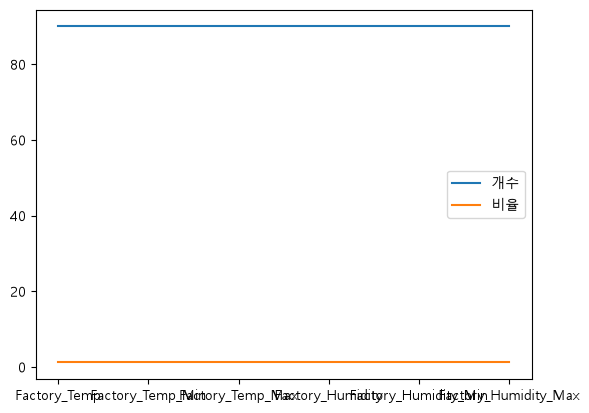

In [119]:
plt.show (cell[cell['개수'] > 0].sort_values(by='개수', ascending=False).plot())
# 큰위 미 X

In [120]:
'+++++'*20

'++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++'

In [121]:
df1 = pd.read_csv("C:\\AI Equipment Failure Prediction\\data\\결측치 잇는데이터\\train.csv")
# 2023 전력사용량 예측 AI 경진대회
# 알고리즘 | 정형 | 시계열 | 에너지 | SMAPE

#[주제]
#전력사용량 예측 AI 모델 개발

In [122]:
df1.shape

(204000, 10)

In [123]:
df1.head()  #일조 : 햇빛이 직접 비친 시간 일사 : 지표면에 도달한 태양에너지의 양

,num_date_time,건물번호,일시,기온(C),강수량(mm),풍속(m/s),습도(%),일조(hr),일사(MJ/m2),전력소비량(kWh)
0,1_20220601 00,1,20220601 00,18.6,NaN,0.9,42.0,NaN,NaN,1085.28
1,1_20220601 01,1,20220601 01,18.0,NaN,1.1,45.0,NaN,NaN,1047.36
2,1_20220601 02,1,20220601 02,17.7,NaN,1.5,45.0,NaN,NaN,974.88
3,1_20220601 03,1,20220601 03,16.7,NaN,1.4,48.0,NaN,NaN,953.76
4,1_20220601 04,1,20220601 04,18.4,NaN,2.8,43.0,NaN,NaN,986.40


In [124]:
missing_count = df1.isna().sum()

In [125]:
missing_count

num_date_time         0
건물번호                  0
일시                    0
기온(C)                 0
강수량(mm)          160069
풍속(m/s)              19
습도(%)                 9
일조(hr)            75182
일사(MJ/m2)         87913
전력소비량(kWh)            0
dtype: int64

In [126]:
per = missing_count / len(df1) * 100
per


num_date_time     0.000000
건물번호              0.000000
일시                0.000000
기온(C)             0.000000
강수량(mm)          78.465196
풍속(m/s)           0.009314
습도(%)             0.004412
일조(hr)           36.853922
일사(MJ/m2)        43.094608
전력소비량(kWh)        0.000000
dtype: float64

In [127]:
celll = pd.DataFrame({'개수': missing_count, '비율': per}).round(2)

In [128]:
celll
# 강수량은 왜 결측치가 많은가? 비가 안오니깐
# 결측치 제거전 생각을 해야할거같음.
# 예를 들어 강수량이 결측치인 경우, 
# 실제로 비가 오지 않았을 가능성이 높음.
# 따라서 단순히 결측치를 제거하기보다는, 
# 결측치를 0으로 대체하는 방법도 고려할 수 있음.

,개수,비율
num_date_time,0,0.00
건물번호,0,0.00
일시,0,0.00
기온(C),0,0.00
강수량(mm),160069,78.47
풍속(m/s),19,0.01
습도(%),9,0.00
일조(hr),75182,36.85
일사(MJ/m2),87913,43.09
전력소비량(kWh),0,0.00


In [129]:
celll[celll['개수'] > 0].round(2)

#강수량,일사 제거 고민, 일조 중요도보고 결정
#결측치가 잇는 행과 비율

,개수,비율
강수량(mm),160069,78.47
풍속(m/s),19,0.01
습도(%),9,0.00
일조(hr),75182,36.85
일사(MJ/m2),87913,43.09


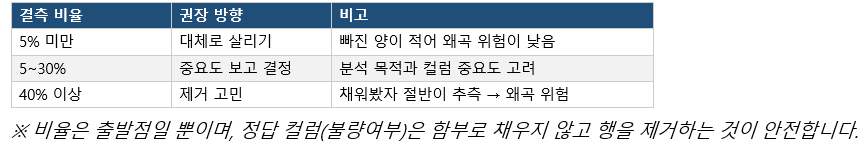

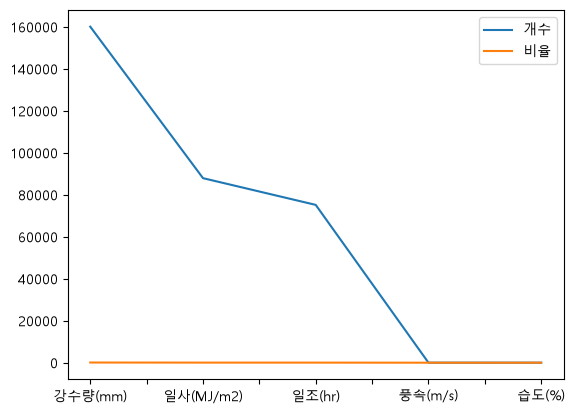

In [130]:
plt.show (celll[celll['개수'] > 0].sort_values(by='개수', ascending=False).plot())


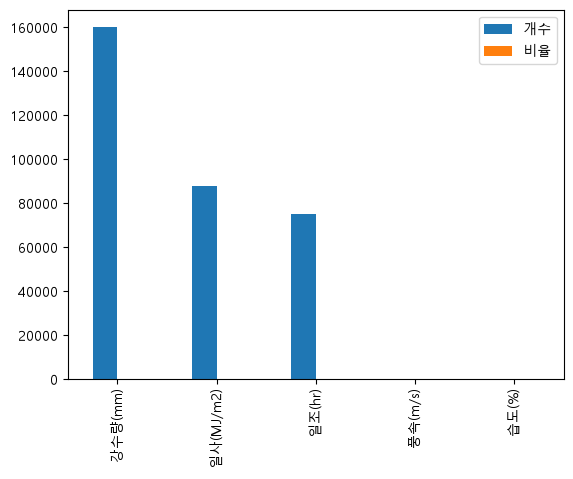

In [131]:
plt.show (celll[celll['개수'] > 0].sort_values(by='개수', ascending=False).plot.bar())


In [132]:
# 데이터 처리 5시 10분

In [133]:
df1.corr(numeric_only=True)['전력소비량(kWh)'].sort_values(ascending=False)

전력소비량(kWh)    1.000000
기온(C)         0.171190
풍속(m/s)       0.109954
일사(MJ/m2)     0.080357
일조(hr)        0.021098
강수량(mm)       0.015386
습도(%)        -0.129546
건물번호         -0.180474
Name: 전력소비량(kWh), dtype: float64

In [134]:
df1 = df1.rename(columns={
    '건물번호': 'building_number',
    '일시': 'date_time',
    '기온(C)': 'temperature',
    '강수량(mm)': 'rainfall',
    '풍속(m/s)': 'windspeed',
    '습도(%)': 'humidity',
    '일조(hr)': 'sunshine',
    '일사(MJ/m2)': 'solar_radiation',
    '전력소비량(kWh)': 'power_consumption'
})
df1.drop('num_date_time', axis = 1, inplace=True)

In [135]:
train=df1.copy()

In [136]:
train.isna().sum()


building_number           0
date_time                 0
temperature               0
rainfall             160069
windspeed                19
humidity                  9
sunshine              75182
solar_radiation       87913
power_consumption         0
dtype: int64

In [137]:
train = pd.read_csv('C:\\AI Equipment Failure Prediction\\data\\결측치 잇는데이터\\train.csv')
test = pd.read_csv('C:\\AI Equipment Failure Prediction\\data\\결측치 잇는데이터\\test.csv')
building_info = pd.read_csv('C:\\AI Equipment Failure Prediction\\data\\결측치 잇는데이터\\building_info.csv')

In [138]:
train = train.rename(columns={
    '건물번호': 'building_number',
    '일시': 'date_time',
    '기온(C)': 'temperature',
    '강수량(mm)': 'rainfall',
    '풍속(m/s)': 'windspeed',
    '습도(%)': 'humidity',
    '일조(hr)': 'sunshine',
    '일사(MJ/m2)': 'solar_radiation',
    '전력소비량(kWh)': 'power_consumption'
})
train.drop('num_date_time', axis = 1, inplace=True)

test = test.rename(columns={
    '건물번호': 'building_number',
    '일시': 'date_time',
    '기온(C)': 'temperature',
    '강수량(mm)': 'rainfall',
    '풍속(m/s)': 'windspeed',
    '습도(%)': 'humidity',
    '일조(hr)': 'sunshine',
    '일사(MJ/m2)': 'solar_radiation',
    '전력소비량(kWh)': 'power_consumption'
})
test.drop('num_date_time', axis = 1, inplace=True)

In [139]:
building_info = building_info.rename(columns={
    '건물번호': 'building_number',
    '건물유형': 'building_type',
    '연면적(m2)': 'total_area',
    '냉방면적(m2)': 'cooling_area',
    '태양광용량(kW)': 'solar_power_capacity',
    'ESS저장용량(kWh)': 'ess_capacity',
    'PCS용량(kW)': 'pcs_capacity'
})

In [140]:
translation_dict = {
    '건물기타': 'Other Buildings',
    '공공': 'Public',
    '대학교': 'University',
    '데이터센터': 'Data Center',
    '백화점및아울렛': 'Department Store and Outlet',
    '병원': 'Hospital',
    '상용': 'Commercial',
    '아파트': 'Apartment',
    '연구소': 'Research Institute',
    '지식산업센터': 'Knowledge Industry Center',
    '할인마트': 'Discount Mart',
    '호텔및리조트': 'Hotel and Resort'
}

building_info['building_type'] = building_info['building_type'].replace(translation_dict)

In [141]:
building_info['solar_power_utility'] = np.where(
    building_info.solar_power_capacity != '-', 1, 0
)

In [142]:
train = pd.merge(train, building_info, on='building_number', how='left')
test = pd.merge(test, building_info, on='building_number', how='left')

In [143]:
train.isna().sum()

building_number              0
date_time                    0
temperature                  0
rainfall                160069
windspeed                   19
humidity                     9
sunshine                 75182
solar_radiation          87913
power_consumption            0
building_type                0
total_area                   0
cooling_area                 0
solar_power_capacity         0
ess_capacity                 0
pcs_capacity                 0
solar_power_utility          0
dtype: int64

In [147]:
train.solar_power_capacity.value_counts()

solar_power_capacity
-         130560
20          4080
50          4080
25          4080
200         4080
40          2040
60          2040
447.2       2040
130.6       2040
56          2040
64.8        2040
70          2040
110         2040
97.65       2040
26.64       2040
30          2040
83.72       2040
35          2040
100.56      2040
46.2        2040
3           2040
9.45        2040
365         2040
14.4        2040
28.44       2040
65          2040
95          2040
60.45       2040
621         2040
100         2040
97.85       2040
98.28       2040
21.6        2040
Name: count, dtype: int64

In [149]:
1/29

0.034482758620689655